In [2]:
import os, sys, re, json, time, random, subprocess, warnings, math
from pathlib import Path
from collections import Counter

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

try:
    import statsmodels.api as sm
except Exception:
    _pip("statsmodels")
    try:
        import statsmodels.api as sm
    except Exception:
        sm = None

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

# ── Config ───────────────────────────────────────────────────────────────────
TEACHER_NAME = "l3cube-pune/hing-bert"
SEEDS        = [13, 42, 2024]     # >=3 seeds; report all of them
EPOCHS       = 3
LR           = 3e-5
BATCH        = 32
MAXLEN       = 160                # SemEval rows reach ~56 tokens; romanized Hindi fragments heavily
WARMUP_FRAC  = 0.10
WEIGHT_DECAY = 0.01
DEV_FRAC     = 0.10
N_BOOT       = 1000
MIN_BIN_N    = 50                 # bins smaller than this are flagged, not hidden
CMI_SOURCE   = "gold"             # "gold" = SemEval gold LID tags (recommended); "pred" = our tagger
SAVE_BEST_MODEL = True            # saves the best-dev seed for Phase 3 (needs ~420 MB)
USE_DRIVE    = True               # mount Google Drive for outputs (survives disconnects)

LABELS = ["negative", "neutral", "positive"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
K = len(LABELS)

# ── Output dir (Drive if possible) ───────────────────────────────────────────
OUT_DIR = Path("./phase2_outputs")
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive/mixing_aware_kd/phase2")
    except Exception as e:
        print(f"(Drive not mounted: {type(e).__name__}; using local {OUT_DIR})")
OUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("./data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

try:
    import torch
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
except Exception:
    torch = None
    DEVICE = "cpu"
print(f"Device: {DEVICE} | outputs: {OUT_DIR.resolve()}")
if str(DEVICE) == "cpu":
    print("WARNING: no GPU detected. Runtime > Change runtime type > T4 GPU before fine-tuning.")

(Drive not mounted: MessageError; using local phase2_outputs)
Device: cuda | outputs: /content/phase2_outputs


In [3]:
import urllib.request

SEMEVAL_DIR = DATA_DIR / "semeval"
if not SEMEVAL_DIR.exists():
    r = subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/singhnivedita/SemEval2020-Task9.git", str(SEMEVAL_DIR)],
                       capture_output=True, text=True)
    print(r.stdout[-300:], r.stderr[-300:])
ORIG_DIR = SEMEVAL_DIR / "Pre Processing Code" / "Original Dataset"
TY_PATH  = SEMEVAL_DIR / "Fully Processed Datasets" / "Ty.txt"   # test labels (Uid,Sentiment)
for p in [ORIG_DIR / "Train.txt", ORIG_DIR / "Validation.txt", ORIG_DIR / "Test.txt", TY_PATH]:
    assert p.exists(), f"Missing {p}. Repo layout changed? List: {os.listdir(SEMEVAL_DIR)}"

LID_DIR = DATA_DIR / "L3Cube-HingLID"; LID_DIR.mkdir(exist_ok=True)
HINGLID_BASE = "https://raw.githubusercontent.com/l3cube-pune/code-mixed-nlp/main/L3Cube-HingLID"
for split in ["train", "validation", "test"]:
    fp = LID_DIR / f"{split}.txt"
    if not fp.exists():
        urllib.request.urlretrieve(f"{HINGLID_BASE}/{split}.txt", str(fp))
    print(f"{split}: {fp.stat().st_size/1024:.0f} KB")

 Cloning into 'data/semeval'...

train: 7600 KB
validation: 1517 KB
test: 1519 KB


In [4]:
URL_RE      = re.compile(r"^(https?://|www\.)\S+$", re.I)
MENTION_RE  = re.compile(r"^@\w+$")
HASHTAG_RE  = re.compile(r"^#\w+")
NONWORD_RE  = re.compile(r"^[\d\W_]+$")        # digits / punctuation / symbols / emoji only
DEVANAGARI_RE = re.compile(r"[\u0900-\u097F]")

def parse_semeval_conll(path):
    sents, cur = [], None
    with open(path, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if line.startswith("meta\t"):
                if cur is not None: sents.append(cur)
                p = line.split("\t")
                cur = {"uid": p[1].strip(),
                       "label": (p[2].strip() if len(p) > 2 and p[2].strip() else None),
                       "tokens": [], "raw_tags": []}
            elif not line.strip():
                continue
            elif cur is not None:
                p = line.split("\t")
                cur["tokens"].append(p[0])
                cur["raw_tags"].append(p[1].strip() if len(p) > 1 else "")
    if cur is not None: sents.append(cur)
    return sents

def norm_gold_tag(t):
    t = re.sub(r"[^A-Za-z]", "", t).lower()      # fixes stray quotes like 'Hin"'
    if t.startswith("hin"): return "HI"
    if t.startswith("eng"): return "EN"
    return "OTHER"                               # 'O', 'EMT', empty

def independent_mask(tokens):
    """True where the token is language-independent (mention, hashtag, URL, punct, number, emoji)."""
    m = [False] * len(tokens)
    for i, t in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if (URL_RE.match(t) or MENTION_RE.match(t) or HASHTAG_RE.match(t)
                or NONWORD_RE.match(t) or prev in ("@", "#")):
            m[i] = True
    return m

def finalize_tags(tokens, base_tags):
    m = independent_mask(tokens)
    return ["OTHER" if m[i] else base_tags[i] for i in range(len(tokens))]

def build_text(tokens):
    """Model input: collapse '@ user' -> '@user', URLs -> 'http'."""
    out, i = [], 0
    while i < len(tokens):
        t = tokens[i]
        if t == "@" and i + 1 < len(tokens):
            out.append("@user"); i += 2; continue
        out.append("http" if URL_RE.match(t) else t)
        i += 1
    return " ".join(out)

def to_df(sents):
    df = pd.DataFrame(sents)
    df["gold_tags"] = [finalize_tags(t, [norm_gold_tag(x) for x in rt])
                       for t, rt in zip(df["tokens"], df["raw_tags"])]
    df["text"] = df["tokens"].apply(build_text)
    df["raw_text"] = df["tokens"].apply(lambda t: " ".join(t))
    return df

raw_train = to_df(parse_semeval_conll(ORIG_DIR / "Train.txt"))
raw_val   = to_df(parse_semeval_conll(ORIG_DIR / "Validation.txt"))
raw_test  = to_df(parse_semeval_conll(ORIG_DIR / "Test.txt"))

ty = pd.read_csv(TY_PATH, dtype=str)
ty_map = dict(zip(ty["Uid"].str.strip(), ty["Sentiment"].str.strip().str.lower()))
raw_test["label"] = raw_test["uid"].map(ty_map)
assert raw_test["label"].notna().all(), "Some test Uids have no label in Ty.txt"

print("=" * 70); print("════ REPORT BACK: SEMEVAL DATA AUDIT ════"); print("=" * 70)
print(f"Original files : train={len(raw_train)}  val={len(raw_val)}  test={len(raw_test)}")
uid_tv = set(raw_train.uid) & set(raw_val.uid)
print(f"Train∩Val by Uid: {len(uid_tv)} of {len(raw_val)} val rows are ALSO in train (leakage if used as dev)")
mm = raw_train.merge(raw_val, on="uid", suffixes=("_tr", "_va"))
print(f"  label disagreement on shared Uids: {(mm.label_tr != mm.label_va).sum()}")
print(f"Train∩Test by Uid: {len(set(raw_train.uid) & set(raw_test.uid))}")
test_texts = set(raw_test.raw_text.str.lower())

pool = pd.concat([raw_train, raw_val], ignore_index=True).drop_duplicates("uid")
pool = pool[~pool.raw_text.str.lower().isin(test_texts)]
pool = pool.drop_duplicates(subset=["raw_text"]).reset_index(drop=True)
print(f"Pooled train+val after Uid/text dedup and test-text removal: {len(pool)}")

pool["y"] = pool["label"].map(LABEL2ID); raw_test["y"] = raw_test["label"].map(LABEL2ID)
assert pool["y"].notna().all() and raw_test["y"].notna().all()
tr_df, dev_df = train_test_split(pool, test_size=DEV_FRAC, stratify=pool["y"], random_state=0)
tr_df, dev_df = tr_df.reset_index(drop=True), dev_df.reset_index(drop=True)
te_df = raw_test.reset_index(drop=True)
for n, d in [("train", tr_df), ("dev", dev_df), ("test", te_df)]:
    dist = d["label"].value_counts(normalize=True).round(3).to_dict()
    print(f"  {n:5s} n={len(d):6d} labels={dist}")
print("Gold tag set after normalization:", Counter(t for ts in tr_df.gold_tags for t in ts))


════ REPORT BACK: SEMEVAL DATA AUDIT ════
Original files : train=15130  val=3000  test=3000
Train∩Val by Uid: 2650 of 3000 val rows are ALSO in train (leakage if used as dev)
  label disagreement on shared Uids: 0
Train∩Test by Uid: 0
Pooled train+val after Uid/text dedup and test-text removal: 15479
  train n= 13931 labels={'neutral': 0.374, 'positive': 0.332, 'negative': 0.294}
  dev   n=  1548 labels={'neutral': 0.374, 'positive': 0.332, 'negative': 0.294}
  test  n=  3000 labels={'neutral': 0.367, 'positive': 0.333, 'negative': 0.3}
Gold tag set after normalization: Counter({'HI': 160334, 'EN': 107627, 'OTHER': 96119})


In [5]:
def parse_hinglid(fp):
    sents, toks, tags = [], [], []
    with open(fp, encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.rstrip("\r\n")
            if not line.strip():
                if toks: sents.append((toks, tags)); toks, tags = [], []
                continue
            p = line.split("\t")
            if len(p) >= 2:
                toks.append(p[0]); tags.append("HI" if p[-1].strip().upper().startswith("HI") else "EN")
    if toks: sents.append((toks, tags))
    return sents

hl = {s: parse_hinglid(LID_DIR / f"{s}.txt") for s in ["train", "validation", "test"]}

class CharLIDTagger:
    """Context-free char n-gram LR over lowercase word forms (HI vs EN). Devanagari -> HI by rule."""
    def __init__(self):
        self.pipe = Pipeline([
            ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=100000, sublinear_tf=True)),
            ("clf", LogisticRegression(max_iter=1000, C=1.0)),
        ])
        self.cache = {}
    def fit(self, words, labels):
        cnt = Counter(zip([w.lower() for w in words], labels))       # dedupe: same fit, far faster
        keys = list(cnt.keys())
        self.pipe.fit([k[0] for k in keys], [k[1] for k in keys], clf__sample_weight=[cnt[k] for k in keys])
        self.cache = {}
        return self
    def predict(self, tokens):
        low = [t.lower() for t in tokens]
        todo = sorted({w for w in low if w not in self.cache and not DEVANAGARI_RE.search(w)})
        if todo:
            for w, p in zip(todo, self.pipe.predict(todo)): self.cache[w] = p
        return ["HI" if DEVANAGARI_RE.search(w) else self.cache[w] for w in low]

t0 = time.time()
tr_words = [w for toks, _ in hl["train"] for w in toks]; tr_labs = [t for _, tags in hl["train"] for t in tags]
tagger = CharLIDTagger().fit(tr_words, tr_labs)
print(f"Tagger trained in {time.time()-t0:.0f}s")

print("=" * 70); print("════ REPORT BACK: LID TAGGER (HingLID gold) ════"); print("=" * 70)
for split in ["validation", "test"]:
    gold = [t for _, tags in hl[split] for t in tags]
    pred = [t for toks, _ in hl[split] for t in tagger.predict(toks)]
    print(f"{split}: token acc={accuracy_score(gold, pred):.4f}  n={len(gold):,}")
    if split == "test":
        print(classification_report(gold, pred, digits=4))
        print("confusion [HI, EN]:\n", confusion_matrix(gold, pred, labels=["HI", "EN"]))


Tagger trained in 13s
════ REPORT BACK: LID TAGGER (HingLID gold) ════
validation: token acc=0.9679  n=193,718
test: token acc=0.9667  n=193,547
              precision    recall  f1-score   support

          EN     0.9507    0.9350    0.9428     56723
          HI     0.9732    0.9799    0.9765    136824

    accuracy                         0.9667    193547
   macro avg     0.9619    0.9574    0.9596    193547
weighted avg     0.9666    0.9667    0.9666    193547

confusion [HI, EN]:
 [[134071   2753]
 [  3688  53035]]


In [6]:
def compute_cmi(tags):
    """CMI in [0,1] over language tokens. For TWO languages the maximum is 0.5."""
    lang = [t for t in tags if t in ("HI", "EN")]
    n, u = len(tags), len(tags) - len(lang)
    if (n - u) <= 1: return 0.0
    return (len(lang) - max(Counter(lang).values())) / (n - u)

def compute_sd(tags):
    """Switch density: share of adjacent LANGUAGE tokens (OTHER skipped) with different languages."""
    lang = [t for t in tags if t in ("HI", "EN")]
    if len(lang) <= 1: return 0.0
    return sum(lang[i] != lang[i + 1] for i in range(len(lang) - 1)) / (len(lang) - 1)

def abs_cmi_bin(c):
    if c == 0: return "mono"
    if c < 0.20: return "low"
    if c < 0.35: return "mid"
    return "high"
ABS_ORDER = ["mono", "low", "mid", "high"]

def quantile_bins(x, q=5):
    """Value-based quantile bins (ties never split). Returns (bin index per item, labels)."""
    x = np.asarray(x, float)
    edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    if len(edges) < 3: return np.zeros(len(x), int), ["all"]
    idx = np.clip(np.digitize(x, edges[1:-1], right=False), 0, len(edges) - 2)
    labels = [f"Q{i+1} [{edges[i]:.2f},{edges[i+1]:.2f}{']' if i == len(edges)-2 else ')'}" for i in range(len(edges) - 1)]
    return idx, labels

def macro_f1_np(y, p, k=K):
    """Macro-F1 over classes present in y (so tiny bins don't get penalized for absent classes)."""
    cm = np.bincount(y * k + p, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, den, out=np.zeros(k), where=den > 0)
    present = cm.sum(1) > 0
    return float(f1[present].mean()) if present.any() else float("nan")

def agreement_report(cmi_g, cmi_p, sd_g, sd_p, title):
    cmi_g, cmi_p, sd_g, sd_p = map(np.asarray, (cmi_g, cmi_p, sd_g, sd_p))
    d = np.abs(cmi_g - cmi_p)
    same_bin = np.mean([abs_cmi_bin(a) == abs_cmi_bin(b) for a, b in zip(cmi_g, cmi_p)])
    print(f"[{title}] n={len(d)}")
    print(f"  CMI  MAE={d.mean():.3f}  P90 |Δ|={np.percentile(d,90):.3f}  share |Δ|>=0.10: {(d>=0.10).mean():.1%}"
          f"  Spearman={spearmanr(cmi_g, cmi_p)[0]:.3f}  same abs-bin: {same_bin:.1%}")
    print(f"  SD   MAE={np.abs(sd_g-sd_p).mean():.3f}  Spearman={spearmanr(sd_g, sd_p)[0]:.3f}")

# (a) HingLID test: gold HI/EN tags vs predicted (no masking; HingLID only has HI/EN)
g_c, p_c, g_s, p_s = [], [], [], []
for toks, gt in hl["test"]:
    pt = tagger.predict(toks)
    g_c.append(compute_cmi(gt)); p_c.append(compute_cmi(pt)); g_s.append(compute_sd(gt)); p_s.append(compute_sd(pt))
print("=" * 70); print("════ REPORT BACK: HOW MUCH LID NOISE MOVES CMI ════"); print("=" * 70)
agreement_report(g_c, p_c, g_s, p_s, "HingLID test: gold vs predicted tags")
print(f"  full-sentence exact tag match: {np.mean([a==b for (t,a),b in zip(hl['test'], [tagger.predict(t) for t,_ in hl['test']])]):.1%}")

# (b) SemEval (in-domain, tweets): our tagger + independence mask vs SemEval gold tags + mask
def add_metrics(df):
    df = df.copy()
    pred_tags = [finalize_tags(t, tagger.predict(t)) for t in df["tokens"]]
    df["pred_tags"] = pred_tags
    for src in ["gold", "pred"]:
        tags = df[f"{src}_tags"]
        df[f"cmi_{src}"] = [compute_cmi(t) for t in tags]
        df[f"sd_{src}"]  = [compute_sd(t) for t in tags]
        df[f"nlang_{src}"] = [sum(x in ("HI", "EN") for x in t) for t in tags]
    df["n_tok"] = df["tokens"].apply(len)
    return df

tr_df, dev_df, te_df = add_metrics(tr_df), add_metrics(dev_df), add_metrics(te_df)
all_eval = pd.concat([tr_df, dev_df, te_df], ignore_index=True)
agreement_report(all_eval.cmi_gold, all_eval.cmi_pred, all_eval.sd_gold, all_eval.sd_pred,
                 "SemEval (all splits): SemEval gold tags vs our tagger")
gtok = [g for gt, pt in zip(all_eval.gold_tags, all_eval.pred_tags) for g, p in zip(gt, pt) if g in ("HI","EN")]
ptok = [p for gt, pt in zip(all_eval.gold_tags, all_eval.pred_tags) for g, p in zip(gt, pt) if g in ("HI","EN")]
print(f"  In-domain token accuracy on language tokens: {accuracy_score(gtok, ptok):.4f} (n={len(gtok):,})")
print("  NOTE: SemEval gold tags are themselves noisy (e.g. 'ko' tagged Eng in the first training row),")
print("  so gold-vs-pred disagreement is an upper bound on tagger error, not pure tagger error.")


════ REPORT BACK: HOW MUCH LID NOISE MOVES CMI ════
[HingLID test: gold vs predicted tags] n=6420
  CMI  MAE=0.024  P90 |Δ|=0.069  share |Δ|>=0.10: 3.3%  Spearman=0.936  same abs-bin: 86.4%
  SD   MAE=0.034  Spearman=0.895
  full-sentence exact tag match: 43.0%
[SemEval (all splits): SemEval gold tags vs our tagger] n=18479
  CMI  MAE=0.086  P90 |Δ|=0.190  share |Δ|>=0.10: 34.1%  Spearman=0.535  same abs-bin: 54.6%
  SD   MAE=0.132  Spearman=0.333
  In-domain token accuracy on language tokens: 0.8147 (n=355,617)
  NOTE: SemEval gold tags are themselves noisy (e.g. 'ko' tagged Eng in the first training row),
  so gold-vs-pred disagreement is an upper bound on tagger error, not pure tagger error.


In [7]:
cmi_col, sd_col, nl_col = f"cmi_{CMI_SOURCE}", f"sd_{CMI_SOURCE}", f"nlang_{CMI_SOURCE}"
print(f"Analysis uses CMI_SOURCE='{CMI_SOURCE}' -> columns {cmi_col}, {sd_col}, {nl_col}")
print("=" * 70); print("════ REPORT BACK: SEMEVAL MIXING DISTRIBUTION (raw text) ════"); print("=" * 70)
rows = []
for n, d in [("train", tr_df), ("dev", dev_df), ("test", te_df)]:
    bins = d[cmi_col].apply(abs_cmi_bin).value_counts(normalize=True)
    rows.append({"split": n, "n": len(d), "mean_CMI": d[cmi_col].mean(), "median_CMI": d[cmi_col].median(),
                 "max_CMI": d[cmi_col].max(), "mean_SD": d[sd_col].mean(), "mean_lang_tokens": d[nl_col].mean(),
                 **{f"%{b}": 100 * bins.get(b, 0) for b in ABS_ORDER}})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nAbsolute bins: mono: CMI=0 | low: (0,0.20) | mid: [0.20,0.35) | high: [0.35,0.50]")
print("(bilingual CMI cannot exceed 0.5, so Phase 1's 'high >= 0.5' bin only held exactly-balanced sentences.)")

cors = te_df[[cmi_col, sd_col, nl_col]].corr(method="spearman").round(3)
print("\nSpearman correlation among CMI / SD / length (test):"); print(cors.to_string())
print("If CMI-length is strongly negative or positive, CMI bins partly measure length: see Cell 10.")


Analysis uses CMI_SOURCE='gold' -> columns cmi_gold, sd_gold, nlang_gold
════ REPORT BACK: SEMEVAL MIXING DISTRIBUTION (raw text) ════
split     n  mean_CMI  median_CMI  max_CMI  mean_SD  mean_lang_tokens  %mono   %low   %mid  %high
train 13931     0.277       0.263      0.5    0.187            19.235  0.567 26.344 45.065 28.024
  dev  1548     0.275       0.261      0.5    0.186            19.384  0.646 26.163 46.576 26.615
 test  3000     0.274       0.261      0.5    0.184            19.217  0.500 27.600 44.733 27.167

Absolute bins: mono: CMI=0 | low: (0,0.20) | mid: [0.20,0.35) | high: [0.35,0.50]
(bilingual CMI cannot exceed 0.5, so Phase 1's 'high >= 0.5' bin only held exactly-balanced sentences.)

Spearman correlation among CMI / SD / length (test):
            cmi_gold  sd_gold  nlang_gold
cmi_gold       1.000    0.412      -0.268
sd_gold        0.412    1.000      -0.320
nlang_gold    -0.268   -0.320       1.000
If CMI-length is strongly negative or positive, CMI bins partly 

In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tok = AutoTokenizer.from_pretrained(TEACHER_NAME)

def encode(texts):
    return tok(list(texts), truncation=True, max_length=MAXLEN)

enc_tr, enc_dev, enc_te = encode(tr_df.text), encode(dev_df.text), encode(te_df.text)
te_df["n_wp"] = [len(x) - 2 for x in enc_te["input_ids"]]
te_df["frag"] = te_df["n_wp"] / te_df[nl_col].clip(lower=1)
print(f"Wordpieces per language token (test): mean={te_df.frag.mean():.2f}; truncated rows: "
      f"{sum(len(x) >= MAXLEN for x in enc_te['input_ids'])}")

class DS(torch.utils.data.Dataset):
    def __init__(self, enc, y): self.enc, self.y, self.keys = enc, list(y), list(enc.keys())
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.keys}; item["labels"] = int(self.y[i]); return item

def collate(batch):
    labels = torch.tensor([b.pop("labels") for b in batch])
    out = tok.pad(batch, return_tensors="pt"); out["labels"] = labels; return out

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

USE_AMP = str(DEVICE) == "cuda"

@torch.no_grad()
def predict_probs(model, loader):
    model.eval(); outs = []
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items() if k != "labels"}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**b).logits
        outs.append(torch.softmax(logits.float(), -1).cpu().numpy())
    return np.concatenate(outs)

BEST = {"dev_f1": -1.0, "seed": None}

def run_seed(seed):
    res_path = OUT_DIR / f"seed{seed}_result.json"
    if res_path.exists():                                      # resume after a Colab disconnect
        r = json.loads(res_path.read_text()); r["test_probs"] = np.load(OUT_DIR / f"seed{seed}_test_probs.npy")
        print(f"seed {seed}: loaded cached result (dev F1={r['dev_f1']:.4f}, test F1={r['test_f1']:.4f})"); return r
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        TEACHER_NAME, num_labels=K, id2label=dict(enumerate(LABELS)), label2id=LABEL2ID).to(DEVICE)
    g = torch.Generator(); g.manual_seed(seed)
    tl = torch.utils.data.DataLoader(DS(enc_tr, tr_df.y), batch_size=BATCH, shuffle=True, collate_fn=collate, generator=g)
    dl = torch.utils.data.DataLoader(DS(enc_dev, dev_df.y), batch_size=128, collate_fn=collate)
    el = torch.utils.data.DataLoader(DS(enc_te, te_df.y), batch_size=128, collate_fn=collate)
    nd = ["bias", "LayerNorm.weight"]
    groups = [{"params": [p for n, p in model.named_parameters() if not any(x in n for x in nd)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if any(x in n for x in nd)], "weight_decay": 0.0}]
    opt = torch.optim.AdamW(groups, lr=LR)
    total = EPOCHS * len(tl)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_FRAC * total), total)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best_f1, best_state, y_dev = -1.0, None, dev_df.y.values.astype(int)
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); run = 0.0
        for step, b in enumerate(tl):
            b = {k: v.to(DEVICE) for k, v in b.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**b).loss
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            run += loss.item()
        f1 = macro_f1_np(y_dev, predict_probs(model, dl).argmax(1))
        print(f"  seed {seed} epoch {ep+1}/{EPOCHS} train_loss={run/len(tl):.4f} dev_macroF1={f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1:
            best_f1 = f1; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    probs = predict_probs(model, el)
    test_f1 = macro_f1_np(te_df.y.values.astype(int), probs.argmax(1))
    if SAVE_BEST_MODEL and best_f1 > BEST["dev_f1"]:
        model.save_pretrained(OUT_DIR / "teacher_best"); tok.save_pretrained(OUT_DIR / "teacher_best")
        BEST.update(dev_f1=best_f1, seed=seed)
    np.save(OUT_DIR / f"seed{seed}_test_probs.npy", probs)
    res = {"seed": seed, "dev_f1": float(best_f1), "test_f1": float(test_f1)}
    res_path.write_text(json.dumps(res))
    del model, opt, best_state; torch.cuda.empty_cache() if USE_AMP else None
    res["test_probs"] = probs
    print(f"seed {seed}: best dev F1={best_f1:.4f} -> test macro-F1={test_f1:.4f}  ({time.time()-t0:.0f}s)")
    return res

seed_results = [run_seed(s) for s in SEEDS]
PROBS = np.stack([r["test_probs"] for r in seed_results])          # (S, N, K)
print(f"\nBest-dev seed saved as Phase 3 teacher: {BEST['seed']} (dev F1={BEST['dev_f1']:.4f})" if BEST["seed"] is not None
      else "\n(teacher_best not re-saved this run: cached seeds were loaded)")

config.json:   0%|          | 0.00/716 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/418 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: l3cube-pune/hing-bert
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  seed 2024 epoch 1/3 train_loss=0.8177 dev_macroF1=0.6893 (57s)
  seed 2024 epoch 2/3 train_loss=0.6429 dev_macroF1=0.6978 (115s)
  seed 2024 epoch 3/3 train_loss=0.4916 dev_macroF1=0.6838 (173s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

seed 2024: best dev F1=0.6978 -> test macro-F1=0.7337  (178s)

Best-dev seed saved as Phase 3 teacher: 2024 (dev F1=0.6978)


In [9]:
rng = np.random.default_rng(0)
y_te = te_df.y.values.astype(int)
P = PROBS.argmax(2)                         # (S, N) per-seed predictions
S = P.shape[0]
ens_pred = PROBS.mean(0).argmax(1)          # seed-ensemble prediction (used for regression only)

def boot_vals(idx, B=N_BOOT):
    vals = np.empty(B)
    for b in range(B):
        s = rng.choice(idx, size=len(idx), replace=True)
        vals[b] = np.mean([macro_f1_np(y_te[s], P[k][s]) for k in range(S)])
    return vals

per_seed = [macro_f1_np(y_te, P[k]) for k in range(S)]
overall_boot = boot_vals(np.arange(len(y_te)))
lo, hi = np.percentile(overall_boot, [2.5, 97.5])
print("=" * 70); print("════ REPORT BACK: TEACHER OVERALL (HingBERT, SemEval-2020 Task 9 Hi-En test) ════"); print("=" * 70)
for r in seed_results:
    print(f"  seed {r['seed']:>5}: dev F1={r['dev_f1']:.4f}  test macro-F1={r['test_f1']:.4f}")
print(f"Test macro-F1 mean over seeds = {np.mean(per_seed):.4f} ± {np.std(per_seed, ddof=1) if S > 1 else 0:.4f} (std)   "
      f"95% bootstrap CI (examples) [{lo:.4f}, {hi:.4f}]")
print(f"Seed-ensemble macro-F1 = {macro_f1_np(y_te, ens_pred):.4f}   accuracy = {np.mean(ens_pred == y_te):.4f}")
print("Per-class report (ensemble):")
print(classification_report(y_te, ens_pred, target_names=LABELS, digits=3))



════ REPORT BACK: TEACHER OVERALL (HingBERT, SemEval-2020 Task 9 Hi-En test) ════
  seed    13: dev F1=0.6947  test macro-F1=0.7340
  seed    42: dev F1=0.6875  test macro-F1=0.7430
  seed  2024: dev F1=0.6978  test macro-F1=0.7337
Test macro-F1 mean over seeds = 0.7369 ± 0.0053 (std)   95% bootstrap CI (examples) [0.7243, 0.7503]
Seed-ensemble macro-F1 = 0.7437   accuracy = 0.7393
Per-class report (ensemble):
              precision    recall  f1-score   support

    negative      0.779     0.752     0.765       900
     neutral      0.653     0.700     0.676      1100
    positive      0.810     0.771     0.790      1000

    accuracy                          0.739      3000
   macro avg      0.747     0.741     0.744      3000
weighted avg      0.743     0.739     0.741      3000



In [10]:
# %% CELL 9: CMI / switch-density / length stratified evaluation
te_df["correct_ens"] = (ens_pred == y_te).astype(int)
te_df["cmi_abs_bin"] = te_df[cmi_col].apply(abs_cmi_bin)

def stratify(name, bin_idx, labels):
    rows, boots = [], {}
    for b, lab in enumerate(labels):
        idx = np.where(bin_idx == b)[0]
        if len(idx) == 0: continue
        ps = [macro_f1_np(y_te[idx], P[k][idx]) for k in range(S)]
        vals = boot_vals(idx); boots[lab] = vals
        l, h = np.percentile(vals, [2.5, 97.5])
        rows.append({"cut": name, "bin": lab, "n": len(idx), "macro_F1": np.mean(ps),
                     "seed_std": np.std(ps, ddof=1) if S > 1 else 0.0, "CI_lo": l, "CI_hi": h,
                     "acc": np.mean([np.mean(P[k][idx] == y_te[idx]) for k in range(S)]),
                     "flag": "SMALL n" if len(idx) < MIN_BIN_N else ""})
    gap = None
    labs = list(boots.keys())
    if len(labs) >= 2:
        d = boots[labs[0]] - boots[labs[-1]]
        gap = (name, labs[0], labs[-1], float(np.mean(d)), *np.percentile(d, [2.5, 97.5]))
    return pd.DataFrame(rows), gap

abs_idx = te_df["cmi_abs_bin"].map({b: i for i, b in enumerate(ABS_ORDER)}).values
abs_labels = ABS_ORDER
cuts = [("CMI (absolute)", abs_idx, abs_labels)]
for nm, col, q in [("CMI (quintile)", cmi_col, 5), ("Switch density (quintile)", sd_col, 5), ("Length: language tokens (tercile)", nl_col, 3)]:
    bi, bl = quantile_bins(te_df[col].values, q); cuts.append((nm, bi, bl))

tables, gaps = [], []
print("=" * 70); print("════ REPORT BACK: WHERE DOES THE TEACHER STRUGGLE? (macro-F1 by bin) ════"); print("=" * 70)
for nm, bi, bl in cuts:
    t, gp = stratify(nm, bi, bl); tables.append(t)
    if gp: gaps.append(gp)
    print(f"\n── {nm} ──"); print(t.drop(columns="cut").round(4).to_string(index=False))
strat_df = pd.concat(tables, ignore_index=True)
print("\nFirst-bin minus last-bin macro-F1 gaps (bootstrap 95% CI; CI excluding 0 = difference unlikely to be noise):")
for nm, a, b, m, l, h in gaps:
    print(f"  {nm}: [{a}] − [{b}] = {m:+.4f}  CI [{l:+.4f}, {h:+.4f}]  {'(excludes 0)' if l > 0 or h < 0 else '(includes 0)'}")
print("\nSpearman between metric and per-example correctness (seed ensemble):")
for nm, col in [("CMI", cmi_col), ("SD", sd_col), ("length", nl_col), ("fragmentation", "frag")]:
    r, p = spearmanr(te_df[col], te_df.correct_ens); print(f"  {nm:14s} rho={r:+.3f}  p={p:.3g}")



════ REPORT BACK: WHERE DOES THE TEACHER STRUGGLE? (macro-F1 by bin) ════

── CMI (absolute) ──
 bin    n  macro_F1  seed_std  CI_lo  CI_hi    acc    flag
mono   15    0.7413    0.0671 0.4599 0.9202 0.7333 SMALL n
 low  828    0.7142    0.0046 0.6842 0.7412 0.7097        
 mid 1342    0.7394    0.0059 0.7159 0.7598 0.7362        
high  815    0.7462    0.0081 0.7210 0.7759 0.7505        

── CMI (quintile) ──
           bin   n  macro_F1  seed_std  CI_lo  CI_hi    acc flag
Q1 [0.00,0.17) 597    0.6963    0.0114 0.6630 0.7288 0.6929     
Q2 [0.17,0.23) 587    0.7201    0.0052 0.6873 0.7512 0.7183     
Q3 [0.23,0.29) 600    0.7407    0.0133 0.7073 0.7721 0.7400     
Q4 [0.29,0.38) 611    0.7691    0.0048 0.7366 0.7979 0.7654     
Q5 [0.38,0.50] 605    0.7386    0.0144 0.7043 0.7691 0.7460     

── Switch density (quintile) ──
           bin   n  macro_F1  seed_std  CI_lo  CI_hi    acc flag
Q1 [0.00,0.09) 600    0.7258    0.0053 0.6916 0.7589 0.7211     
Q2 [0.09,0.14) 534    0.7311    0.

In [11]:
# %% CELL 10: Do CMI/SD matter after controlling for length and tokenizer fragmentation?
print("=" * 70); print("════ REPORT BACK: CONFOUND CHECK ════"); print("=" * 70)
X = te_df[[cmi_col, sd_col, nl_col, "frag"]].copy(); X.columns = ["CMI", "SD", "length", "fragmentation"]
Xz = (X - X.mean()) / X.std(ddof=0)
print("Predictors are z-scored; odds ratio is per +1 SD. Outcome: seed-ensemble prediction correct (1/0).")
print("CMI and SD are correlated, so read their coefficients with that in mind (spearman CMI~SD = "
      f"{spearmanr(X.CMI, X.SD)[0]:.2f}).")
if sm is not None:
    fit = sm.Logit(te_df.correct_ens.values, sm.add_constant(Xz.values)).fit(disp=0)
    ci = np.exp(fit.conf_int())
    out = pd.DataFrame({"odds_ratio": np.exp(fit.params[1:]), "CI_lo": ci[1:, 0], "CI_hi": ci[1:, 1], "p": fit.pvalues[1:]}, index=Xz.columns)
    print(out.round(4).to_string())
else:
    lr = LogisticRegression(C=1e6, max_iter=1000).fit(Xz.values, te_df.correct_ens.values)
    print(pd.DataFrame({"odds_ratio": np.exp(lr.coef_[0])}, index=Xz.columns).round(4).to_string())
    print("(statsmodels unavailable: no CIs or p-values)")

li, ll = quantile_bins(te_df[nl_col].values, 3); ci_, cl = quantile_bins(te_df[cmi_col].values, 3)
print("\nmacro-F1 by length tercile (rows) x CMI tercile (cols); n in brackets:")
grid = pd.DataFrame(index=ll, columns=cl, dtype=object)
for a in range(len(ll)):
    for b in range(len(cl)):
        idx = np.where((li == a) & (ci_ == b))[0]
        grid.iloc[a, b] = "n/a" if len(idx) == 0 else f"{np.mean([macro_f1_np(y_te[idx], P[k][idx]) for k in range(S)]):.3f} [{len(idx)}]"
print(grid.to_string())



════ REPORT BACK: CONFOUND CHECK ════
Predictors are z-scored; odds ratio is per +1 SD. Outcome: seed-ensemble prediction correct (1/0).
CMI and SD are correlated, so read their coefficients with that in mind (spearman CMI~SD = 0.41).
               odds_ratio   CI_lo   CI_hi       p
CMI                1.0740  0.9803  1.1767  0.1252
SD                 0.9739  0.8859  1.0706  0.5835
length             0.9219  0.8357  1.0169  0.1039
fragmentation      1.0046  0.9153  1.1027  0.9232

macro-F1 by length tercile (rows) x CMI tercile (cols); n in brackets:
                 Q1 [0.00,0.21) Q2 [0.21,0.32) Q3 [0.32,0.50]
Q1 [2.00,17.00)     0.699 [184]    0.763 [271]    0.752 [444]
Q2 [17.00,23.00)    0.741 [351]    0.720 [396]    0.752 [317]
Q3 [23.00,33.00]    0.692 [425]    0.720 [372]    0.779 [240]


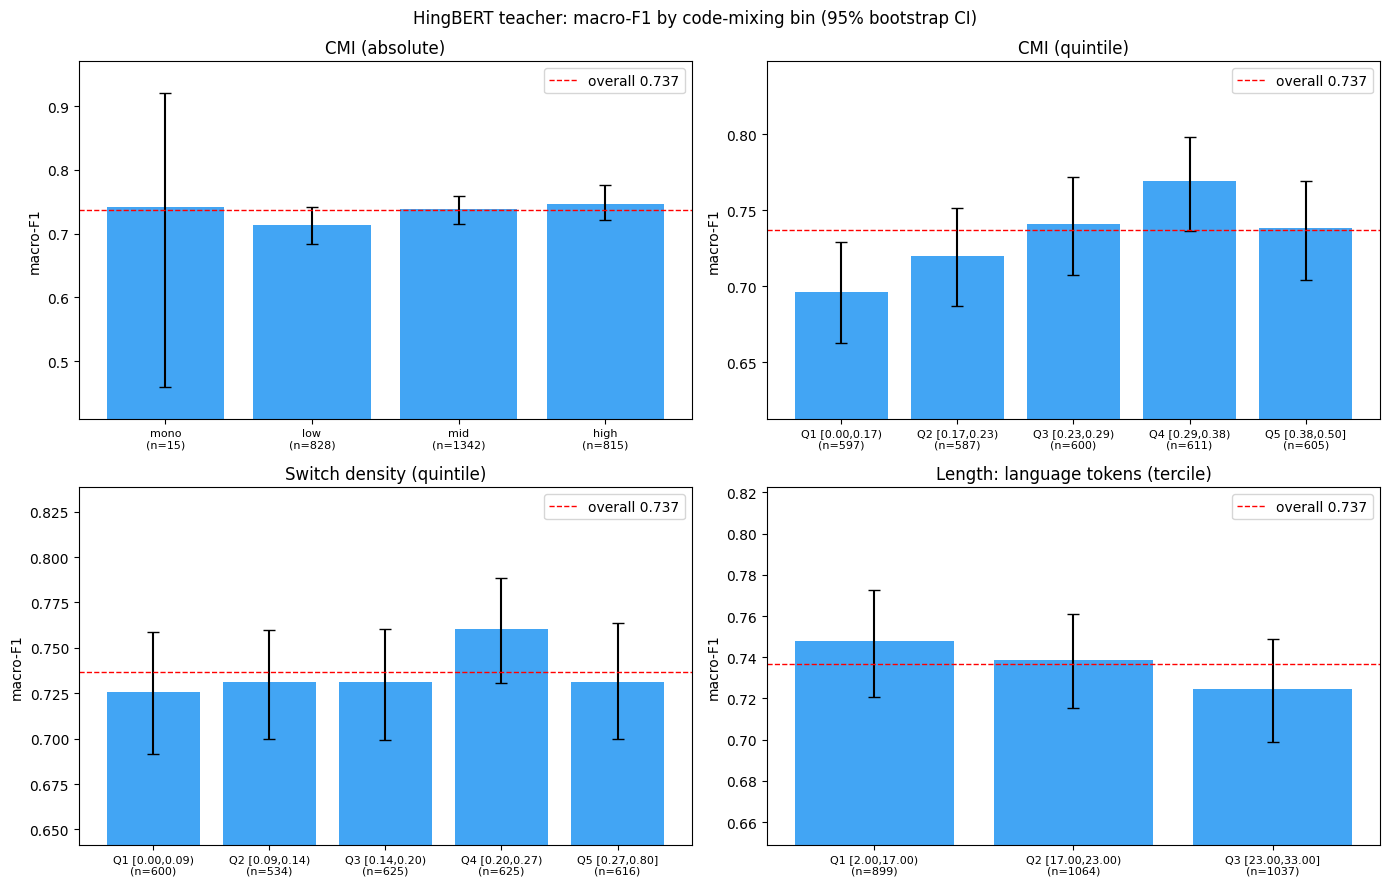

In [13]:
# %% CELL 11: Figures
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (nm, bi, bl) in zip(axes.ravel(), cuts):
    t = strat_df[strat_df.cut == nm]
    x = np.arange(len(t))
    ax.bar(x, t.macro_F1, yerr=[t.macro_F1 - t.CI_lo, t.CI_hi - t.macro_F1], capsize=4, color="#2196F3", alpha=0.85)
    ax.axhline(np.mean(per_seed), color="red", ls="--", lw=1, label=f"overall {np.mean(per_seed):.3f}")
    ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(t.bin, t.n)], fontsize=8)
    ax.set_ylim(max(0, t.CI_lo.min() - 0.05), min(1, t.CI_hi.max() + 0.05)); ax.set_ylabel("macro-F1"); ax.set_title(nm); ax.legend()
plt.suptitle("HingBERT teacher: macro-F1 by code-mixing bin (95% bootstrap CI)")
plt.tight_layout(); plt.savefig(FIG_DIR / "teacher_stratified.png", dpi=150, bbox_inches="tight"); plt.show()



In [14]:
# %% CELL 12: Save artifacts + final summary
meta_cols = ["uid", "label", "y", "raw_text", cmi_col, sd_col, nl_col, "n_tok", "n_wp", "frag", "cmi_abs_bin", "correct_ens"]
meta = te_df[meta_cols].copy(); meta["ens_pred"] = ens_pred
for k, r in enumerate(seed_results): meta[f"pred_seed{r['seed']}"] = P[k]
meta.to_csv(OUT_DIR / "teacher_test_predictions.csv", index=False)
np.save(OUT_DIR / "teacher_test_probs_all_seeds.npy", PROBS)
strat_df.to_csv(OUT_DIR / "teacher_stratified_results.csv", index=False)
tr_df[["uid", "label", "y"]].to_csv(OUT_DIR / "split_train_uids.csv", index=False)
dev_df[["uid", "label", "y"]].to_csv(OUT_DIR / "split_dev_uids.csv", index=False)
summary = {
    "teacher": TEACHER_NAME, "seeds": SEEDS, "epochs": EPOCHS, "lr": LR, "batch": BATCH, "maxlen": MAXLEN,
    "cmi_source": CMI_SOURCE, "n_train": len(tr_df), "n_dev": len(dev_df), "n_test": len(te_df),
    "test_macro_f1_per_seed": per_seed, "test_macro_f1_mean": float(np.mean(per_seed)),
    "test_macro_f1_ci95": [float(lo), float(hi)], "ensemble_macro_f1": macro_f1_np(y_te, ens_pred),
    "best_seed_for_phase3": BEST["seed"],
}
(OUT_DIR / "phase2_summary.json").write_text(json.dumps(summary, indent=2))
print("=" * 70); print("════ PHASE 2 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════"); print("=" * 70)
print(json.dumps(summary, indent=2)); print(f"\nSaved to: {OUT_DIR.resolve()}")

════ PHASE 2 DONE — SEND ALL ════ REPORT BACK ════ BLOCKS ABOVE ════
{
  "teacher": "l3cube-pune/hing-bert",
  "seeds": [
    13,
    42,
    2024
  ],
  "epochs": 3,
  "lr": 3e-05,
  "batch": 32,
  "maxlen": 160,
  "cmi_source": "gold",
  "n_train": 13931,
  "n_dev": 1548,
  "n_test": 3000,
  "test_macro_f1_per_seed": [
    0.7339644507356505,
    0.7429697191433817,
    0.7337417057843415
  ],
  "test_macro_f1_mean": 0.7368919585544579,
  "test_macro_f1_ci95": [
    0.7242768023502492,
    0.7502975654204452
  ],
  "ensemble_macro_f1": 0.7436993903421619,
  "best_seed_for_phase3": 2024
}

Saved to: /content/phase2_outputs
